# 性能分析（DeepMIMO)

In [2]:
import itertools
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import glob
from typing import Optional

import h5py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

from models import ACoupler

# ================= 配置区域 (请根据实际情况修改) =================
# EXP_DIR = './exp/legacy_deepmimoO1'
EXP_DIR = './exp/my_train'
TEST_FOLDER = "test"
TEST_DATASET = "32antx32car_3p5GHz_40MHz_R501-1400_V1_23-9-25"

INPUT_CONFIG_LABELS = {
    '2antx2car': r'2 antennas $\times$ 2 carriers',
    '3antx3car': r'3 antennas $\times$ 3 carriers',
    '4antx4car': r'4 antennas $\times$ 4 carriers',
}

TRAIN_DATA_CONFIG_LABELS = {
    'data1000_Ncur0or1': '1000 training sub-areas',
    'data2000_Ncur0or1': '2000 training sub-areas',
    'data3000_Ncur0or1': '3000 training sub-areas',
}

# EXP_DIR = './exp/DICHASUS/0152-0157_DirectSample512to32'
# TEST_FOLDER = 'test_5k'
# TEST_DATASET = '0152-0157_DirectSample512to32'
# MODEL_DIR_NAMES = {
#     # 'ConvCoupler256L8': 'ConvCoupler_Ncur0or1_batch100_data1000',
#     'ConvCouplerL8': 'ConvCouplerL8d128_Ncur0or1_batch100_data1000',
#     'ConvCouplerL16': 'ConvCouplerL16d128_Ncur0or1_batch100_data1000',
#     'ACouplerNoAgg': 'ACoupler_d128_noAgghead1_Ncur0or1_batch100_data1000',
#     'ACouplerAgg': 'ACoupler_head1_Ncur0or1_batch100_data1000',
#     # 'ACoupler256': '2_ACoupler_d256_noAgghead1_Ncur0or1_batch100_data1000',
#     # 'ACoupler256drop': '2_ACoupler_d256_dropout_noAgghead1_Ncur0or1_batch100_data1000',
#     'AFCoupler': 'AFCoupler_Ncur0or1_batch100_data1000_TransformerLR',
#     # 'AFCoupler256': '2_AFCoupler_d256_Ncur0or1_batch100_data1000',
#     'ACDNet': 'ACDNet_Ncur0or1_batch500_data1000',
#     'ACDNet1024': 'ACDNet_d1024_Ncur0or1_batch500_data1000',
#     'RCDNet': 'RCDNet_Ncur0or1_batch500_data1000',
#     'RCDNet1024': 'RCDNet_d1024_Ncur0or1_batch500_data1000'
#     # 'AFCDNet': 'AFCDNet_ckpt5w'
# }
# MODEL_DIR_NAMES = {
#     'ConvCouplerL8': 'ConvCouplerL8d128_Ncur0or1_batch100_data2000',
#     # 'ConvCouplerL16': 'ConvCouplerL16d128_Ncur0or1_batch100_data2000',
#     'ACouplerNoAgg': 'ACoupler_d128_noAgghead1_Ncur0or1_batch100_data2000',
#     # 'ACouplerAgg': 'ACoupler_head1_Ncur0or1_batch100_data2000',
#     'AFCoupler': 'AFCoupler_Ncur0or1_batch100_data2000_TransformerLR',
#     'RCDNet': 'RCDNet_Ncur0or1_batch500_data2000',
#     # 'RCDNet1024': 'RCDNet_d1024_Ncur0or1_batch500_data2000'
#     'ACDNet': 'ACDNet_Ncur0or1_batch500_data2000',
#     # 'ACDNet1024': 'ACDNet_d1024_Ncur0or1_batch500_data2000',
#     # 'AFCDNet': 'AFCDNet_ckpt5w',
#     'ConvLSTM': 'ConvLSTM-depth2-ch16_Ncur0or1_batch100_data2000',
# }
# MODEL_DIR_NAMES = {
#     # 'ConvCoupler256': 'ConvCoupler_Ncur0or1_batch100',
#     # 'ACoupler128': 'ACoupler_head1_Ncur0or1_batch100',
#     # 'ACoupler256': '2_ACoupler_d256_noAgghead1_Ncur0or1_batch100_data3000',
#     'AFCoupler128': 'AFCoupler_Ncur0or1_batch100_data3000_TransformerLR',
#     # 'AFCoupler256': '2_AFCoupler_d256_Ncur0or1_batch100_data3000',
#     'ACDNet': 'ACDNet_Ncur0or1_batch500_data3000',
#     'RCDNet': 'RCDNet_Ncur0or1_batch500_data3000',
#     'ConvLSTM': 'ConvLSTM-depth2-ch16_Ncur0or1_batch100_data3000'
#     # 'AFCDNet': 'AFCDNet_ckpt5w'
# }

# MODEL_DIR_NAMES = {
#     'AFCoupler': 'AFCoupler_Ncur0or1_batch100_data2000',
#     'ACDNet': 'ACDNet_d512_Ncur0or1_batch500_data2000',
# }

# MODEL_DIR_NAMES = {
#     'AFCoupler': 'AFCoupler',
#     'ACDNet': 'ACDNet',
# }

MODEL_DIR_NAMES_FULL = {
    'ConvCoupler': 'ConvCoupler-L8d128',
    # 'ConvCouplerL16': 'ConvCouplerL16d128_Ncur0or1_batch100_data2000',
    'ACoupler': 'ACoupler-d128_noAgghead1',
    'AFCoupler': 'AFCoupler-d128',
    'RCDNet': 'RCDNet-d512_batch500',
    'ACDNet': 'ACDNet-d512_batch500',
    'RCDNet-Big': 'RCDNet-d1024_batch500',
    'ACDNet-Big': 'ACDNet-d1024_batch500',
    # 'AFCDNet': 'AFCDNet_ckpt5w',
    'ConvLSTM': 'ConvLSTM-depth2-ch16',
}

MODEL_DIR_NAMES = {
    'ConvCoupler': 'ConvCoupler-L8d128',
    # 'ConvCouplerL16': 'ConvCouplerL16d128_Ncur0or1_batch100_data2000',
    'ACoupler': 'ACoupler-d128_noAgghead1',
    'AFCoupler': 'AFCoupler-d128',
    'RCDNet': 'RCDNet-d512_batch500',
    # 'RCDNet1024': 'RCDNet_d1024_Ncur0or1_batch500_data2000'
    'ACDNet': 'ACDNet-d512_batch500',
    # 'ACDNet1024': 'ACDNet_d1024_Ncur0or1_batch500_data2000',
    # 'AFCDNet': 'AFCDNet_ckpt5w',
    'ConvLSTM': 'ConvLSTM-depth2-ch16',
}

SCENARIO_NAMES = {
    'specifictest_mobile': 'mobile',
    'specifictest_static': 'quasi-static'
}

# 输出保存目录（包括图片和csv）
SAVE_DIR = "./results/DeepmimoO1"

# ================= 绘图样式设置 (复刻旧代码风格) =================
plot_config = {
    "font.family": 'Times New Roman',
    "font.size": 14,
    # "axes.labelsize": 16,
    # "xtick.labelsize": 14,
    # "ytick.labelsize": 14,
    # "legend.fontsize": 14,
    # "lines.linewidth": 2,
    # "axes.grid": True,
    # "grid.alpha": 0.5,
    # "grid.linestyle": '--'
}
rcParams.update(plot_config)

# 定义颜色 (复刻 Set1)
# COLORS = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
LINESTYLES = ['-', '--']
MARKERS = ['o', '^', 's', 'd', 'v', 'x']
palette1 = plt.get_cmap('Set1')
palette2 = plt.get_cmap('Pastel1')
linecolors = [palette1(1), palette1(2), palette1(4), palette1(6), palette1(3), palette1(8)]
facecolors = [palette2(1), palette2(2), palette2(4)]


#TODO: 后续将 train_data_config 改为必选参数
def load_csv(input_config, model_dir_name, scenario, task,
             train_data_config: Optional[str]=None):
    """ 辅助函数：返回 csv 读取 """
    if train_data_config is None:
        path = os.path.join(EXP_DIR, f'input_{input_config}', model_dir_name, 'test',
                            TEST_DATASET, scenario, f'{task}.csv')
    else:
        assert isinstance(train_data_config, str)
        path = os.path.join(EXP_DIR, f'input_{input_config}', train_data_config,
                            model_dir_name, 'test',
                            TEST_DATASET, scenario, f'{task}.csv')

    if not os.path.exists(path):
        print(f"⚠️ Warning: File not found: {path}")
        return None
    else:
        return pd.read_csv(path)


def save_plot(filename):
    """ 保存为 pdf, jpg, eps """
    os.makedirs(SAVE_DIR, exist_ok=True)
    base = os.path.join(SAVE_DIR, filename)
    plt.savefig(f"{base}.pdf", bbox_inches='tight')
    plt.savefig(f"{base}.jpg", bbox_inches='tight', dpi=300)
    # plt.savefig(f"{base}.eps", bbox_inches='tight') # 需要时取消注释
    print(f"✅ Saved: {base}.pdf/jpg")


def save_csv(df, filename):
    """ 保存为 pdf, jpg, eps """
    if not filename.endswith('.csv'):
        filename += '.csv'
    os.makedirs(SAVE_DIR, exist_ok=True)
    base = os.path.join(SAVE_DIR, filename)
    df.to_csv(base, index=False)
    print(f"✅ Saved: {base}")


## 绘制训练收敛曲线

Plotting History Length Impact...
✅ Saved: ./results/DeepmimoO1/O1data2k_convergence.pdf/jpg


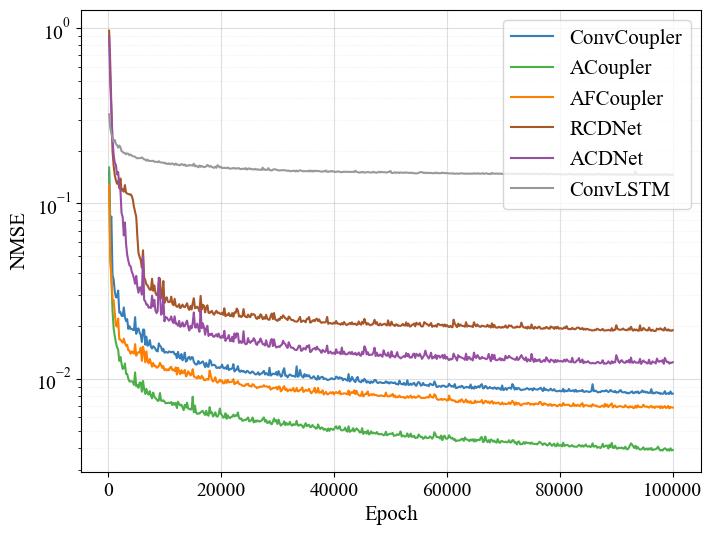

In [50]:
def plot_convergence(
        input_config: str, train_data_config: str,
        is_mix: bool = False,
        fig_name: str = "NMSE_pastlen",
        is_save: bool = True):
    """ 绘制训练收敛曲线 """
    print("Plotting History Length Impact...")
    plt.figure(figsize=(8, 6))
    plt.yscale('log')

    for i, (model_name, model_dir_name) in enumerate(MODEL_DIR_NAMES.items()):
        path = os.path.join(EXP_DIR, f'input_{input_config}', train_data_config,
                            model_dir_name, 'log', 'val_metrics.csv')
        df = pd.read_csv(path)
        mobile_df = df[df['mode'] == 'mobile']
        static_df = df[df['mode'] == 'static']

        if is_mix:
            nmse_data = (mobile_df['nmse'].to_numpy() + static_df['nmse'].to_numpy()) / 2
            plt.plot(mobile_df['epoch'], nmse_data, label=f'{model_name}',
                     linestyle=LINESTYLES[0],
                     color=linecolors[i])
        else:
            plt.plot(mobile_df['epoch'], mobile_df['nmse'],
                     label=f'{model_name} (mobile)',
                     linestyle=LINESTYLES[0],
                     color=linecolors[i])
            plt.plot(static_df['epoch'], static_df['nmse'],
                     label=f'{model_name} (qusi-static)',
                     linestyle=LINESTYLES[1],
                     color=linecolors[i])

    plt.ylabel("NMSE", fontsize=15)
    plt.xlabel("Epoch", fontsize=15)
    plt.grid(alpha=0.4)
    plt.grid(True, which="major", axis='y', linestyle='-', alpha=0.4)
    plt.grid(True, which="minor", axis='y', linestyle=':', alpha=0.2)
    plt.legend(prop={'size': 15}, ncol=1)
    if is_save:
        save_plot(f"{fig_name}")
    plt.show()
    plt.close()


input_config = '3antx3car'
train_data_config = 'data2000_Ncur0or1'
fig_name = 'O1data2k_convergence'
plot_convergence(input_config, train_data_config,
                 is_mix=True, fig_name=fig_name, is_save=True)

## NMSE 的 CDF 曲线

Plotting NMSE CDF...
✅ Saved: ./results/DeepmimoO1/O1data2k_NMSE_CDF.pdf/jpg


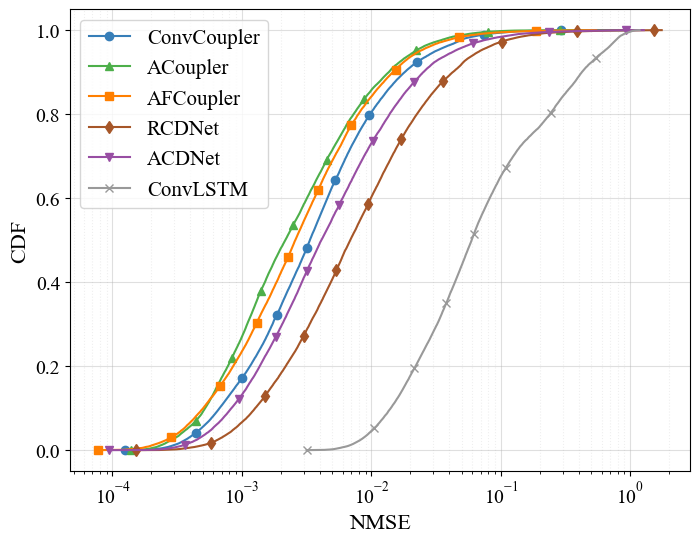

In [49]:
def plot_nmse_cdf(
        input_config: str, train_data_config: str, scenarios: list[str],
        log_scale_x: bool = False,
        fig_name: str = "NMSE_CDF",
        is_save: bool = True):
    """ 绘制 NMSE 的 CDF 曲线 """
    print("Plotting NMSE CDF...")
    plt.figure(figsize=(8, 6))

    for i, (model_name, model_dir_name) in enumerate(MODEL_DIR_NAMES.items()):
        nmse_list = []
        for scenario in scenarios:
            df = load_csv(input_config, model_dir_name, scenario, 'standard',
                          train_data_config=train_data_config)
            nmse_data = df['nmse'].values
            nmse_list.append(nmse_data)
        nmse_list = np.concatenate(nmse_list)
        sorted_data = np.sort(nmse_list)

        yvals = np.arange(len(sorted_data)) / float(len(sorted_data) - 1)
        plt.plot(sorted_data, yvals, label=model_name,
                 marker=MARKERS[i % len(MARKERS)],
                 color=linecolors[i],
                 markevery=0.1)

    if log_scale_x:
        plt.xscale('log')
    else:
        plt.xlim(0, 1)  # 线性刻度时的常规范围

    # plt.ylabel('Cumulative Probability Distribution', fontsize=15)
    plt.ylabel('CDF', fontsize=16)
    plt.xlabel('NMSE', fontsize=16)
    plt.grid(True, alpha=0.4) # which="both" 确保对数刻度的次要网格线也显示
    plt.grid(True, which="major", axis='x', linestyle='-', alpha=0.4)
    plt.grid(True, which="minor", axis='x', linestyle=':', alpha=0.2)
    plt.legend(prop={'size': 15}, ncol=1)

    if is_save:
        save_plot(fig_name)
    plt.show()
    plt.close()


input_config = '3antx3car'
train_data_config = 'data2000_Ncur0or1'
scenarios = ['specifictest_static', 'specifictest_mobile']
log_scale_x = True
fig_name = 'O1data2k_NMSE_CDF'
plot_nmse_cdf(input_config, train_data_config, scenarios,
              log_scale_x=log_scale_x, fig_name=fig_name, is_save=True)

## 噪声鲁棒性曲线

Plotting Noise Robustness (Add Noise to: past)...
✅ Saved: ./results/DeepmimoO1/O1data2k_NMSE_noise_disturb_past.pdf/jpg


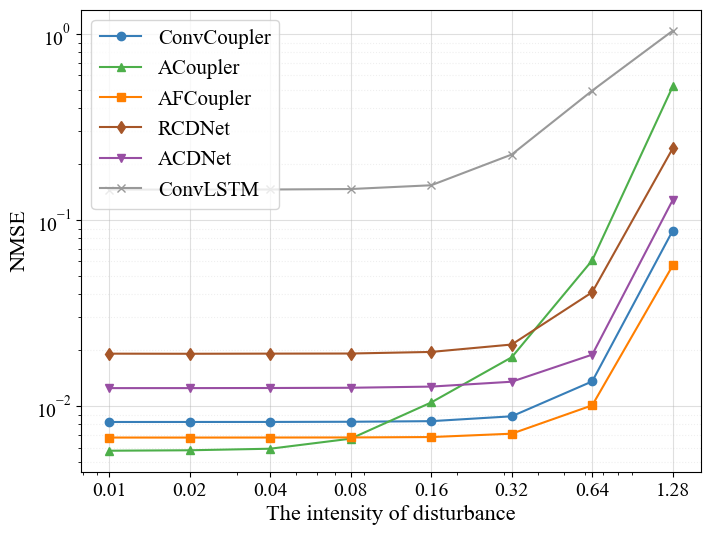

Plotting Noise Robustness (Add Noise to: all)...
✅ Saved: ./results/DeepmimoO1/O1data2k_NMSE_noise_disturb_all.pdf/jpg


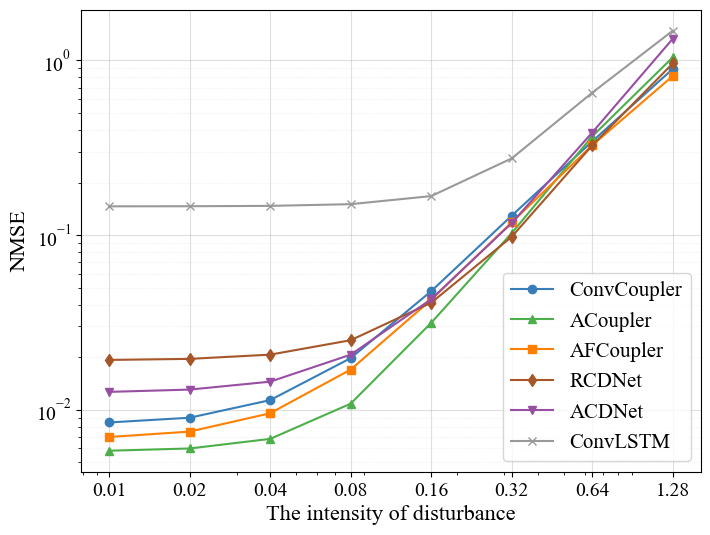

In [6]:
def plot_noise_robustness(
        input_config: str, train_data_config: str, scenarios: list[str],
        is_mix: bool = False,
        noise_target: str = 'all',
        legend_loc: str = 'upper left',
        fig_name: str = "NMSE_noise_disturb",
        is_save: bool = True):
    """ 绘制噪声鲁棒性曲线 (target='all' or 'past') """
    print(f"Plotting Noise Robustness (Add Noise to: {noise_target})...")
    plt.figure(figsize=(8, 6))
    plt.yscale('log')
    plt.xscale('log')

    for i, (model_name, model_dir_name) in enumerate(MODEL_DIR_NAMES.items()):
        if is_mix:
            # --- Case 1: 混合模式 (Mix) ---
            # 收集该模型在所有 scenario 下的数据
            df_list = []
            for scenario in scenarios:
                df = load_csv(input_config, model_dir_name, scenario, 'production_noise',
                              train_data_config=train_data_config)
                sub_df = df[df['noise_target'] == noise_target]
                df_list.append(sub_df)

            # 合并所有场景的数据
            if df_list:
                full_df = pd.concat(df_list)
                grouped = full_df.groupby('noise_level')['nmse'].mean().sort_index()
                x = grouped.index
                y = grouped.values
                label = f'{model_name}'
                plt.plot(x[1:], y[1:], label=label,
                         marker=MARKERS[i % len(MARKERS)],
                         linestyle=LINESTYLES[0],
                         color=linecolors[i])

        else:
            # --- Case 2: 原始模式 (Split) ---
            for j, scenario in enumerate(scenarios):
                scenario_label = SCENARIO_NAMES[scenario]
                df = load_csv(input_config, model_dir_name, scenario, 'production_noise',
                              train_data_config=train_data_config)
                sub_df = df[df['noise_target'] == noise_target]   # 筛选加噪目标类型

                # 按噪声等级分组取平均
                grouped = sub_df.groupby('noise_level')['nmse'].mean().sort_index()

                x = grouped.index
                y = grouped.values

                label = f'{model_name} ({scenario_label})'
                # 去掉开头的 0
                plt.plot(x[1:], y[1:], label=label,
                         marker=MARKERS[j % len(MARKERS)],
                         linestyle=LINESTYLES[j % len(LINESTYLES)],
                         color=linecolors[i])

    plt.ylabel("NMSE", fontsize=16)
    plt.xlabel("The intensity of disturbance", fontsize=16)
    # plt.ylim(0.001, 2)
    plt.xticks([0.01, 0.02, 0.04, 0.08, 0.16, 0.32, 0.64, 1.28],
               [0.01, 0.02, 0.04, 0.08, 0.16, 0.32, 0.64, 1.28])
    # plt.xlim(0.008, 1.5)
    plt.grid(alpha=0.4)
    plt.grid(True, which="major", axis='y', linestyle='-', alpha=0.4)
    plt.grid(True, which="minor", axis='y', linestyle=':', alpha=0.2)
    plt.legend(fontsize=15, loc=legend_loc)
    if is_save:
        save_plot(f"{fig_name}_{noise_target}")
    plt.show()
    plt.close()


input_config = '3antx3car'
train_data_config = 'data2000_Ncur0or1'
scenarios = ['specifictest_static', 'specifictest_mobile']
fig_name = 'O1data2k_NMSE_noise_disturb'
plot_noise_robustness(input_config, train_data_config, scenarios,
                      is_mix=True, noise_target='past',
                      legend_loc='upper left',
                      fig_name=fig_name, is_save=True)
plot_noise_robustness(input_config, train_data_config, scenarios,
                      is_mix=True, noise_target='all',
                      legend_loc='lower right',
                      fig_name=fig_name, is_save=True)

## 历史长度影响曲线

Plotting History Length Impact...
✅ Saved: ./results/DeepmimoO1/O1data2k_NMSE_pastlen.pdf/jpg


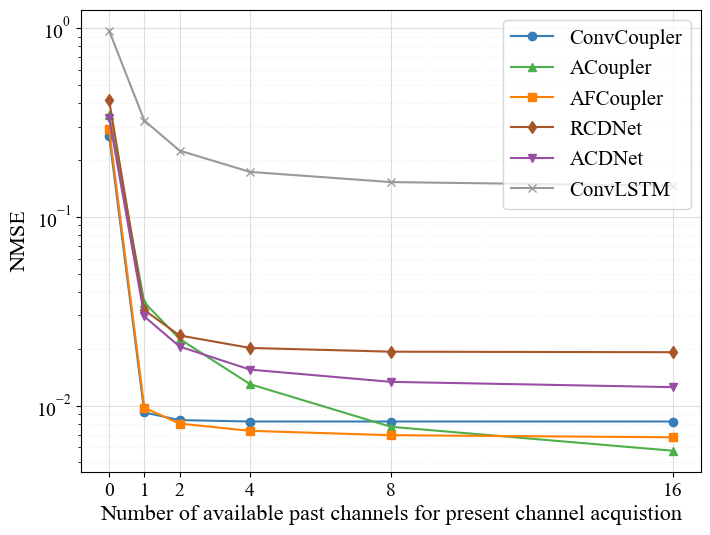

Plotting History Length Impact...
✅ Saved: ./results/DeepmimoO1/O1data2k_NMSE_pastlen_coupler_static_mobile.pdf/jpg


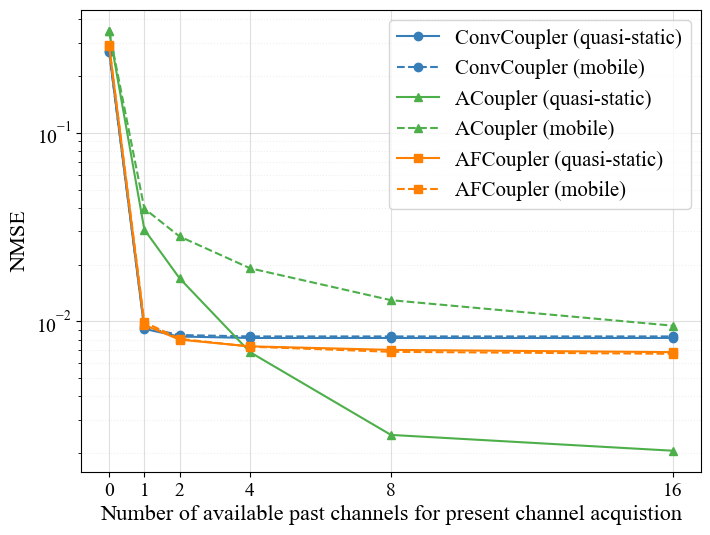

In [5]:
def plot_history_length(
        input_config: str, train_data_config: str, scenarios: list[str],
        is_mix: bool = False,
        active_model_names: Optional[list[str]] = None,
        fig_name: str = "NMSE_pastlen",
        is_save: bool = True):
    """ 5. 绘制历史长度影响曲线 """
    print("Plotting History Length Impact...")
    plt.figure(figsize=(8, 6))
    plt.yscale('log')

    for i, (model_name, model_dir_name) in enumerate(MODEL_DIR_NAMES.items()):
        if active_model_names is not None and model_name not in active_model_names:
            continue

        if is_mix:
            # --- Case 1: 混合模式 (Mix) ---
            # 收集该模型在所有 scenario 下的数据
            df_list = []
            for scenario in scenarios:
                df = load_csv(input_config, model_dir_name, scenario, 'history_len',
                              train_data_config=train_data_config)
                df_list.append(df)

            # 合并所有场景的数据
            if df_list:
                full_df = pd.concat(df_list)
                grouped = full_df.groupby('past_len')['nmse'].mean().sort_index()
                x = grouped.index
                y = grouped.values
                label = f'{model_name}'
                plt.plot(x, y, label=label,
                         marker=MARKERS[i % len(MARKERS)],
                         linestyle=LINESTYLES[0],
                         color=linecolors[i])

        else:
            for j, scenario in enumerate(scenarios):
                scenario_label = SCENARIO_NAMES[scenario]
                df = load_csv(input_config, model_dir_name, scenario, 'history_len',
                              train_data_config=train_data_config)

                grouped = df.groupby('past_len')['nmse'].mean().sort_index()
                x = grouped.index
                y = grouped.values

                label = f'{model_name} ({scenario_label})'
                plt.plot(x, y, label=label,
                         marker=MARKERS[i % len(MARKERS)],
                         linestyle=LINESTYLES[j % len(LINESTYLES)],
                         color=linecolors[i])

    plt.ylabel("NMSE", fontsize=16)
    plt.xlabel("Number of available past channels for present channel acquistion", fontsize=16)
    plt.xticks([0, 1, 2, 4, 8, 16])
    plt.grid(alpha=0.4)
    plt.grid(True, which="major", axis='y', linestyle='-', alpha=0.4)
    plt.grid(True, which="minor", axis='y', linestyle=':', alpha=0.2)
    plt.legend(prop={'size': 15}, ncol=1)
    if is_save:
        save_plot(f"{fig_name}")
    plt.show()
    plt.close()


input_config = '3antx3car'
train_data_config = 'data2000_Ncur0or1'
scenarios = ['specifictest_static', 'specifictest_mobile']
fig_name = 'O1data2k_NMSE_pastlen'
plot_history_length(input_config, train_data_config, scenarios,
                    is_mix=True,
                    # active_model_names=['ConvCoupler', 'ACoupler', 'AFCoupler'],
                    fig_name=fig_name,
                    is_save=True)
fig_name = 'O1data2k_NMSE_pastlen_coupler_static_mobile'
plot_history_length(input_config, train_data_config, scenarios,
                    is_mix=False,
                    active_model_names=['ConvCoupler', 'ACoupler', 'AFCoupler'],
                    fig_name=fig_name,
                    is_save=True)

## 不同输入维度、不同模型的 NMSE 性能条形图（旧）

In [ ]:
def plot_nmse_schemes_bar(input_configs: list[str], scenarios: list[str],
                          is_mix: bool = False,  # <--- 新增选项
                          fig_name: str = "NMSE_bar_for_schemes_and_configs",
                          is_save: bool = True,
                          q_lower: float = 0.25,
                          q_upper: float = 0.75):
    """
    绘制不同 Schemes 的 NMSE 对比柱状图，并添加分位数误差棒
    q_lower: 下分位数 (如 0.25)
    q_upper: 上分位数 (如 0.75)
    """
    print("Plotting NMSE Schemes Bar Chart with Quantiles...")
    model_names = list(MODEL_DIR_NAMES.keys())
    model_scenario_list = list(itertools.product(model_names, scenarios))
    scheme_names = [f'{model_name}\n({SCENARIO_NAMES[scenario]})' for (model_name, scenario) in model_scenario_list]
    # means = {k: [] for k in input_configs}
    mid_vals = {k: [] for k in input_configs}
    # 存储误差棒数据，结构为 {config: [[lower_diffs...], [upper_diffs...]]}
    yerrs = {k: [[], []] for k in input_configs}

    for input_config in input_configs:
        for model_name, scenario in model_scenario_list:
            model_dir_name = MODEL_DIR_NAMES[model_name]
            df = load_csv(input_config, model_dir_name, scenario, 'standard')

            # 计算统计量
            # mean_val = df['nmse'].mean()
            mid_val = df['nmse'].median()
            q_low_val = df['nmse'].quantile(q_lower)
            q_high_val = df['nmse'].quantile(q_upper)

            # means[input_config].append(mean_val)
            mid_vals[input_config].append(mid_val)
            # Matplotlib 的 yerr 需要的是相对于均值的长度 (positive values)
            # 下误差 = Mean - Lower Quantile
            # 上误差 = Upper Quantile - Mean
            # 注意：NMSE 分布可能严重偏态，导致 Mean > Upper Quantile，此时需取绝对值或允许负值视需求而定
            # 这里按标准逻辑计算距离：
            err_low = mid_val - q_low_val
            err_high = q_high_val - mid_val

            yerrs[input_config][0].append(err_low)
            yerrs[input_config][1].append(err_high)

    x = np.arange(len(model_scenario_list))
    width = 0.15
    dw = 1.6 * width
    dw_list = (np.arange(len(input_configs)) - (len(input_configs) - 1) / 2) * dw

    plt.figure(figsize=(12, 5))
    plt.yscale('log')

    for i, input_config in enumerate(input_configs):
        # 将误差列表转换为 numpy array，形状为 (2, N)
        current_yerr = np.array(yerrs[input_config])

        # 简单处理：如果 Mean 在分位数范围之外导致距离为负，绘图可能出错，通常用 abs 处理或检查数据分布
        # 考虑到是对数坐标，且 NMSE > 0，这里直接传入
        plt.bar(x + dw_list[i], mid_vals[input_config],
                width=width, edgecolor='black',
                color=facecolors[i], linewidth=1,
                label=INPUT_CONFIG_LABELS[input_config],
                yerr=current_yerr,  # 添加误差棒
                capsize=4,  # 误差棒帽大小
                error_kw={'elinewidth': 1, 'ecolor': 'black', 'alpha': 0.7}) # 误差棒样式细节

    plt.xticks(ticks=np.arange(len(scheme_names)), labels=scheme_names, rotation=0)
    plt.ylabel('NMSE',fontsize=15)
    plt.ylim(top=10**-1)
    plt.grid(alpha=0.4, axis='y') # 通常只开 y 轴网格比较清晰
    plt.legend(fontsize=16)
    if is_save:
        save_plot(fig_name)
    plt.show()
    plt.close()


input_configs = ['2antx2car', '3antx3car', '4antx4car']
scenarios = ['specifictest_static', 'specifictest_mobile']
fig_name = 'O1_NMSE_bar_for_schemes_and_configs'
plot_nmse_schemes_bar(input_configs, scenarios, fig_name=fig_name, is_save=False)



## 不同输入维度、不同模型的 NMSE 性能箱线图

Plotting NMSE Schemes Boxplot (Past Len: 16, Mixed Scenarios, Show Outliers: False)...
✅ Saved: ./results/DeepmimoO1/O1_NMSE_boxplot_by_input_dim_mix_len16.pdf/jpg


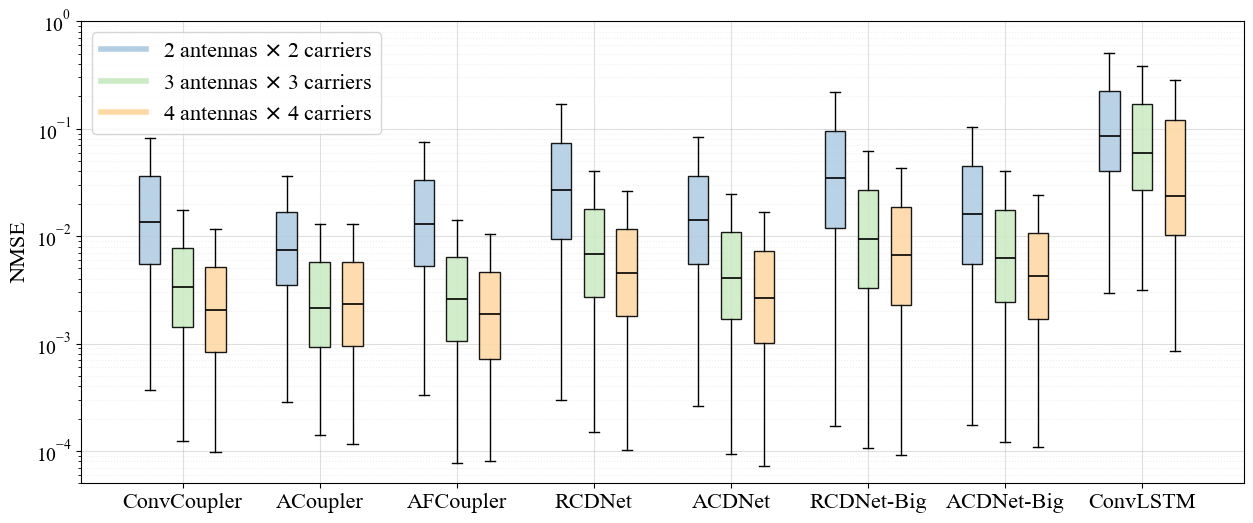


NMSE Statistics Summary (Past Len: 16)
                Input_Config_Label        Model     Scenario  Past_Len     Mean  Median (50%)  Q1 (25%)  Q3 (75%)      Min      Max      Std  Count
0   2 antennas $\times$ 2 carriers  ConvCoupler  Mixed (All)        16 4.06e-02      1.36e-02  5.51e-03  3.62e-02 3.71e-04 2.19e+00 1.20e-01  40000
1   2 antennas $\times$ 2 carriers     ACoupler  Mixed (All)        16 1.68e-02      7.49e-03  3.48e-03  1.67e-02 2.84e-04 2.00e+00 4.29e-02  40000
2   2 antennas $\times$ 2 carriers    AFCoupler  Mixed (All)        16 3.40e-02      1.30e-02  5.31e-03  3.30e-02 3.30e-04 2.09e+00 8.55e-02  40000
3   2 antennas $\times$ 2 carriers       RCDNet  Mixed (All)        16 6.96e-02      2.67e-02  9.43e-03  7.31e-02 2.98e-04 2.20e+00 1.40e-01  40000
4   2 antennas $\times$ 2 carriers       ACDNet  Mixed (All)        16 4.08e-02      1.41e-02  5.45e-03  3.65e-02 2.65e-04 2.09e+00 1.16e-01  40000
5   2 antennas $\times$ 2 carriers   RCDNet-Big  Mixed (All)        16 8

In [10]:
def plot_nmse_schemes_boxplot(
        input_configs: list[str], train_data_config: str, scenarios: list[str],
        past_len: int,          # <--- [修改1] 新增参数：指定历史长度
        model_dir_names: dict,
        is_mix: bool = False,
        show_outliers: bool = False,
        fig_name: str = "NMSE_boxplot_by_input_dim",
        is_save: bool = True):
    """
    绘制不同 Schemes 在特定 past_len 下的 NMSE 分组箱线图
    """
    mode_str = "Mixed Scenarios" if is_mix else "Separate Scenarios"
    print(f"Plotting NMSE Schemes Boxplot (Past Len: {past_len}, {mode_str}, Show Outliers: {show_outliers})...")

    model_names = list(model_dir_names.keys())
    stats_results = []  # <--- [修改] 用于存储统计结果

    # --- 1. 确定 X 轴的分类 (Schemes) ---
    if is_mix:
        # 混合模式：X 轴仅为模型名
        scheme_keys = model_names
        scheme_labels = [model_name for model_name in model_names]
    else:
        # 分离模式：X 轴为模型+场景
        scheme_keys = list(itertools.product(model_names, scenarios))
        scheme_labels = [f'{m}\n({SCENARIO_NAMES[s]})' for (m, s) in scheme_keys]

    # --- 2. 准备绘图坐标 ---
    x = np.arange(len(scheme_keys))
    width = 0.15  # 箱子的宽度
    dw = 1.6 * width  # 组间间距因子
    dw_list = (np.arange(len(input_configs)) - (len(input_configs) - 1) / 2) * dw

    plt.figure(figsize=(15, 6))
    plt.yscale('log')

    # --- 3. 遍历每个配置 (Input Config) 进行数据收集与绘图 ---
    for i, input_config in enumerate(input_configs):
        data_for_config = []  # 存储当前 input_config 下，所有 X 轴位置的数据

        # 获取友好的 Label 用于 CSV 记录
        input_config_label = INPUT_CONFIG_LABELS.get(input_config, input_config)

        # 遍历 X 轴的每一个位置 (Scheme)
        for key in scheme_keys:
            current_data = np.array([]) # 当前这一组的数据容器
            if is_mix:
                # --- [混合模式逻辑] ---
                model_name = key   # key 是 model_name
                model_dir = model_dir_names[model_name]
                current_model_name = model_name
                current_scenario_name = "Mixed (All)"
                temp_data_list = []
                for scenario in scenarios:
                    # 加载 'history_len' 类型的文件，并筛选特定的 past_len
                    df = load_csv(input_config, model_dir, scenario, 'history_len',
                                  train_data_config=train_data_config)
                    df_filtered = df[df['past_len'] == past_len]
                    if not df_filtered.empty:
                        temp_data_list.append(df_filtered['nmse'].values)

                # 合并该模型在所有场景下的数据
                if temp_data_list:
                    current_data = np.concatenate(temp_data_list)
                #     data_for_config.append(combined_data)
                # else:
                #     data_for_config.append([]) # 防空处理

            else:
                # --- [分离模式逻辑] ---
                model_name, scenario = key
                model_dir = model_dir_names[model_name]
                current_model_name = model_name
                current_scenario_name = SCENARIO_NAMES.get(scenario, scenario)
                df = load_csv(input_config, model_dir, scenario, 'history_len',
                              train_data_config=train_data_config)
                df_filtered = df[df['past_len'] == past_len]
                if not df_filtered.empty:
                    current_data = df_filtered['nmse'].values
                # else:
                #     data_for_config.append([])

            # --- [修改] 收集数据用于绘图和统计 ---
            if current_data.size > 0:
                data_for_config.append(current_data)
                stats_results.append({
                    'Input_Config': input_config,
                    'Input_Config_Label': input_config_label,
                    'Model': current_model_name,
                    'Scenario': current_scenario_name,
                    'Past_Len': past_len,
                    'Count': len(current_data),
                    'Mean': np.mean(current_data),
                    'Std': np.std(current_data),
                    'Min': np.min(current_data),
                    'Q1 (25%)': np.percentile(current_data, 25),
                    'Median (50%)': np.median(current_data),
                    'Q3 (75%)': np.percentile(current_data, 75),
                    'Max': np.max(current_data)
                })

        # --- 4. 绘制箱线图 ---
        positions = x + dw_list[i]

        bp = plt.boxplot(
            data_for_config,
            positions=positions,
            widths=width,
            patch_artist=True,
            showfliers=show_outliers,
            flierprops={
                'marker': 'o', 'markerfacecolor': 'gray', 'markeredgecolor': 'none',
                'markersize': 2, 'alpha': 0.1
            },
            medianprops={'color': 'black', 'linewidth': 1.2}
        )

        # 给箱子上色
        for patch in bp['boxes']:
            patch.set_facecolor(facecolors[i]) # 假设 facecolors 是外部定义的全局变量
            patch.set_alpha(0.9)

        # 添加图例 Dummy
        label_text = INPUT_CONFIG_LABELS[input_config]
        plt.plot([], [], color=facecolors[i], label=label_text, linewidth=4)

    # --- 5. 装饰 ---
    plt.xticks(ticks=x, labels=scheme_labels, rotation=0, fontsize=16)
    plt.ylabel(f'NMSE', fontsize=16) # 更新 Y 轴标签提示 past_len
    plt.ylim(bottom=5e-5, top=1e0)
    plt.grid(True, alpha=0.4)
    plt.grid(True, which="major", axis='y', linestyle='-', alpha=0.4)
    plt.grid(True, which="minor", axis='y', linestyle=':', alpha=0.2)
    plt.legend(fontsize=16, loc='upper left')
    # plt.title(f"NMSE Performance at History Length = {past_len}") # 可选：加个标题

    # 更新文件名以包含 past_len
    # 文件名生成
    suffix = "_mix" if is_mix else ""
    final_fig_name = f"{fig_name}{suffix}_len{past_len}"

    if is_save:
        save_plot(final_fig_name)
    plt.show()
    plt.close()

    # 文件名生成
    suffix = "_mix" if is_mix else ""
    final_fig_name = f"{fig_name}{suffix}_len{past_len}"

    # --- [修改] 保存 CSV 统计数据 ---
    csv_filename = f"{final_fig_name}_stats.csv"
    df_stats = pd.DataFrame(stats_results)

    # 调整列顺序
    cols = ['Input_Config_Label', 'Model', 'Scenario', 'Past_Len',
            'Mean', 'Median (50%)', 'Q1 (25%)', 'Q3 (75%)',
            'Min', 'Max', 'Std', 'Count']
    # 确保只选择存在的列（防止有些列名拼写错误）
    cols = [c for c in cols if c in df_stats.columns]
    df_stats = df_stats[cols]

    print("\n" + "="*80)
    print(f"NMSE Statistics Summary (Past Len: {past_len})")
    print("="*80)
    pd.set_option('display.max_rows', None)
    pd.set_option('display.width', 1000)
    pd.set_option('display.float_format', '{:.2e}'.format) # 使用科学计数法显示 NMSE，因为通常很小
    print(df_stats)
    print("="*80 + "\n")

    if is_save:
        save_csv(df_stats, csv_filename)

# --- 运行调用示例 ---
input_configs = ['2antx2car', '3antx3car', '4antx4car']
train_data_config = 'data2000_Ncur0or1'
scenarios = ['specifictest_static', 'specifictest_mobile']
target_past_len = 16  # <--- 指定你要画的历史长度，例如 12

plot_nmse_schemes_boxplot(
    input_configs,
    train_data_config,
    scenarios,
    model_dir_names=MODEL_DIR_NAMES_FULL,
    past_len=target_past_len,  # 传入参数
    is_mix=True,
    fig_name='O1_NMSE_boxplot_by_input_dim',
    is_save=True
)

## 不同输入维度、不同模型的 $\rho$ 统计

In [11]:
def calculate_rho_stats_by_input_dim(
        input_configs: list[str],
        train_data_config: str,
        scenarios: list[str],
        past_len: int,          # <--- [修改1] 新增参数
        model_dir_names: dict,
        csv_name: str = "Corr_stats_by_input_dim"):
    """
    统计不同输入维度 (Input Configs) 下，特定 past_len 的 Correlation Coefficient (Rho)。
    数据源：使用 'history_len' 任务数据进行筛选。
    """
    print(f"Calculating Rho Statistics by Input Dimension (Past Len: {past_len})...")

    results = []
    model_names = list(model_dir_names.keys())

    # --- 1. 遍历 输入配置 ---
    for input_config in input_configs:
        config_label = INPUT_CONFIG_LABELS.get(input_config, input_config)

        # --- 2. 遍历 模型 ---
        for model_name in model_names:
            model_dir = model_dir_names[model_name]
            all_scenarios_data = [] # 用于收集该模型在该输入配置下，所有场景的原始数据（用于计算 Mix）

            # --- 3. 遍历 场景 (Separate) ---
            for scenario in scenarios:
                # [修改2] 读取 'history_len' 而不是 'standard'
                df = load_csv(input_config, model_dir, scenario, 'history_len',
                              train_data_config=train_data_config)
                # [修改3] 筛选特定的 past_len
                # if df is not None and 'past_len' in df.columns and 'corr' in df.columns:
                sub_df = df[df['past_len'] == past_len]
                if not sub_df.empty:
                    corr_values = sub_df['corr'].values
                    mean_corr = np.mean(corr_values)
                    # 收集用于 Mixed 计算
                    all_scenarios_data.append(corr_values)
                    # 记录单场景结果
                    results.append({
                        'Input_Config': input_config,
                        'Input_Label': config_label,
                        'Model': model_name,
                        'Scenario': SCENARIO_NAMES.get(scenario, scenario),
                        'Past_Len': past_len,
                        'Type': 'Separate',
                        'Average_Rho': mean_corr
                    })

            # --- 4. 计算 混合场景 (Mixed) ---
            if all_scenarios_data:
                combined_data = np.concatenate(all_scenarios_data)
                mixed_mean_corr = np.mean(combined_data)
                results.append({
                    'Input_Config': input_config,
                    'Input_Label': config_label,
                    'Model': model_name,
                    'Scenario': 'Mixed (All)',
                    'Past_Len': past_len,
                    'Type': 'Mixed',
                    'Average_Rho': mixed_mean_corr
                })

    # --- 5. 整理与输出 ---
    if not results:
        print(f"No results found for past_len={past_len}.")
        return

    df_results = pd.DataFrame(results)

    # 排列列顺序
    cols = ['Input_Label', 'Model', 'Scenario', 'Past_Len', 'Average_Rho', 'Type', 'Input_Config']
    # 确保只列出存在的列
    cols = [c for c in cols if c in df_results.columns]
    df_results = df_results[cols]

    # 5.1 打印到控制台
    print("\n" + "="*80)
    print(f"Correlation Statistics Summary (Past Len: {past_len})")
    print("="*80)
    pd.set_option('display.max_rows', None)
    pd.set_option('display.width', 1000)
    pd.set_option('display.float_format', '{:.4f}'.format)
    print(df_results)
    print("="*80 + "\n")

    # 5.2 保存到 CSV (自动把 past_len 加到文件名中)
    if csv_name.endswith('.csv'):
        final_csv_name = csv_name.replace('.csv', f'_len{past_len}.csv')
    else:
        final_csv_name = f"{csv_name}_len{past_len}.csv"

    save_csv(df_results, final_csv_name)


# --- 运行调用 ---
input_configs = ['2antx2car', '3antx3car', '4antx4car']
train_data_config = 'data2000_Ncur0or1'
scenarios = ['specifictest_static', 'specifictest_mobile']
target_past_len = 16  # <--- [设置] 你想统计的历史长度

calculate_rho_stats_by_input_dim(
    input_configs,
    train_data_config,
    scenarios,
    model_dir_names=MODEL_DIR_NAMES_FULL,
    past_len=target_past_len,  # 传入参数
    csv_name="O1_Corr_stats_by_input_dims"
)

Calculating Rho Statistics by Input Dimension (Past Len: 16)...

Correlation Statistics Summary (Past Len: 16)
                       Input_Label        Model      Scenario  Past_Len  Average_Rho      Type Input_Config
0   2 antennas $\times$ 2 carriers  ConvCoupler  quasi-static        16       0.9850  Separate    2antx2car
1   2 antennas $\times$ 2 carriers  ConvCoupler        mobile        16       0.9839  Separate    2antx2car
2   2 antennas $\times$ 2 carriers  ConvCoupler   Mixed (All)        16       0.9844     Mixed    2antx2car
3   2 antennas $\times$ 2 carriers     ACoupler  quasi-static        16       0.9967  Separate    2antx2car
4   2 antennas $\times$ 2 carriers     ACoupler        mobile        16       0.9914  Separate    2antx2car
5   2 antennas $\times$ 2 carriers     ACoupler   Mixed (All)        16       0.9940     Mixed    2antx2car
6   2 antennas $\times$ 2 carriers    AFCoupler  quasi-static        16       0.9883  Separate    2antx2car
7   2 antennas $\times$ 2

## 不同数据量、不同模型的 NMSE 箱线图

Plotting NMSE by Train Config (Mixed Scenarios, Show Outliers: False)...
✅ Saved: ./results/DeepmimoO1/O1_NMSE_boxplot_by_training_size_mix_3antx3car.pdf/jpg


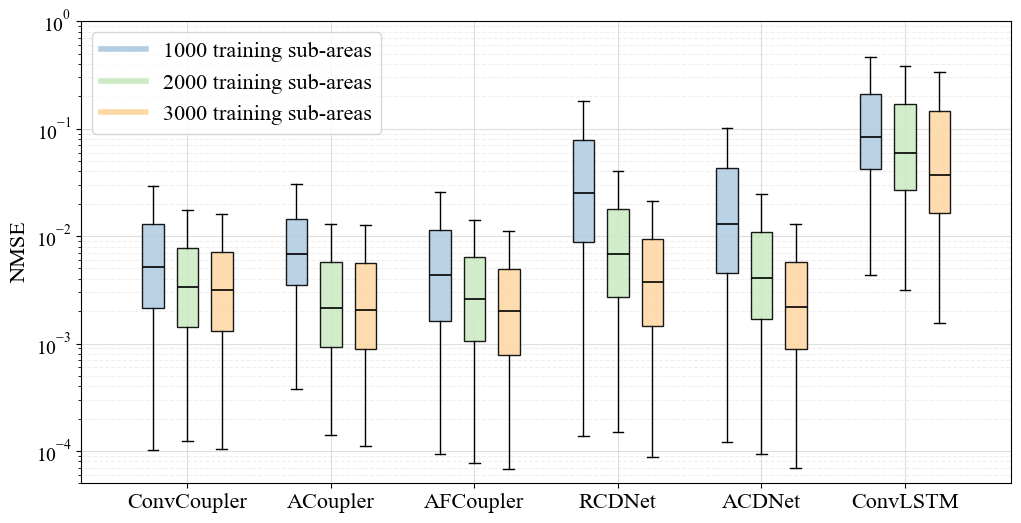


NMSE Statistics Summary (By Train Config: 3antx3car)
                Input_Config_Label       Train_Config_Label        Model     Scenario     Mean  Median (50%)  Q1 (25%)  Q3 (75%)      Min      Max      Std  Count
0   3 antennas $\times$ 3 carriers  1000 training sub-areas  ConvCoupler  Mixed (All) 1.64e-02      5.11e-03  2.13e-03  1.29e-02 1.03e-04 2.16e+00 5.95e-02  40000
1   3 antennas $\times$ 3 carriers  1000 training sub-areas     ACoupler  Mixed (All) 1.56e-02      6.82e-03  3.48e-03  1.43e-02 3.76e-04 1.41e+00 3.88e-02  40000
2   3 antennas $\times$ 3 carriers  1000 training sub-areas    AFCoupler  Mixed (All) 1.43e-02      4.35e-03  1.61e-03  1.13e-02 9.46e-05 2.39e+00 5.45e-02  40000
3   3 antennas $\times$ 3 carriers  1000 training sub-areas       RCDNet  Mixed (All) 8.58e-02      2.52e-02  8.84e-03  7.80e-02 1.39e-04 3.15e+00 1.80e-01  40000
4   3 antennas $\times$ 3 carriers  1000 training sub-areas       ACDNet  Mixed (All) 6.75e-02      1.30e-02  4.49e-03  4.34e-02 1.

In [4]:
def plot_nmse_boxplot_by_train_config(
        input_config: str, train_data_configs: list[str], scenarios: list[str],
        is_mix: bool = False,
        show_outliers: bool = False,
        fig_name: str = "NMSE_boxplot_by_train_data",
        is_save: bool = True):
    """
    绘制在特定 Input Config 下，不同 Training Data Configs 对 Schemes 的 NMSE 影响分组箱线图
    并增加数据统计及 CSV 保存功能。
    """
    mode_str = "Mixed Scenarios" if is_mix else "Separate Scenarios"
    print(f"Plotting NMSE by Train Config ({mode_str}, Show Outliers: {show_outliers})...")

    model_names = list(MODEL_DIR_NAMES.keys())
    stats_results = []  # <--- [新增] 用于存储统计结果

    # --- 1. 确定 X 轴的分类 (Schemes) ---
    if is_mix:   # 混合模式：X 轴仅为模型名
        scheme_keys = model_names
        scheme_labels = [model_name for model_name in model_names]
    else:   # 分离模式：X 轴为模型+场景
        scheme_keys = list(itertools.product(model_names, scenarios))
        scheme_labels = [f'{m}\n({SCENARIO_NAMES[s]})' for (m, s) in scheme_keys]

    # --- 2. 准备绘图坐标 ---
    x = np.arange(len(scheme_keys))
    width = 0.15
    dw = 1.6 * width
    dw_list = (np.arange(len(train_data_configs)) - (len(train_data_configs) - 1) / 2) * dw

    plt.figure(figsize=(12, 6))
    plt.yscale('log')

    # 获取友好的 Input Label
    input_config_label = INPUT_CONFIG_LABELS.get(input_config, input_config)

    # --- 3. 遍历每个训练配置 (Train Data Config) 进行数据收集与绘图 ---
    for i, t_config in enumerate(train_data_configs):
        data_for_config = []
        t_config_label = TRAIN_DATA_CONFIG_LABELS.get(t_config, t_config)

        # 遍历 X 轴的每一个 Scheme
        for key in scheme_keys:
            current_data = np.array([])

            if is_mix:   # key 是 model_name
                model_name = key
                model_dir = MODEL_DIR_NAMES[model_name]
                current_model_name = model_name
                current_scenario_name = "Mixed (All)"

                # 混合模式：读取该模型在所有 scenario 下的数据并合并
                temp_data_list = []
                for scenario in scenarios:
                    df = load_csv(input_config, model_dir, scenario, 'standard',
                                  train_data_config=t_config)
                    if df is not None and not df.empty:
                        temp_data_list.append(df['nmse'].values)

                if temp_data_list:
                    current_data = np.concatenate(temp_data_list)
            else:
                # 分离模式
                model_name, scenario = key
                model_dir = MODEL_DIR_NAMES[model_name]
                current_model_name = model_name
                current_scenario_name = SCENARIO_NAMES.get(scenario, scenario)

                df = load_csv(input_config, model_dir, scenario, 'standard',
                              train_data_config=t_config)
                if df is not None and not df.empty:
                    current_data = df['nmse'].values

            # --- [新增] 收集数据用于绘图和统计 ---
            if current_data.size > 0:
                data_for_config.append(current_data)
                stats_results.append({
                    'Input_Config': input_config,
                    'Input_Config_Label': input_config_label,
                    'Train_Config': t_config,
                    'Train_Config_Label': t_config_label,
                    'Model': current_model_name,
                    'Scenario': current_scenario_name,
                    'Count': len(current_data),
                    'Mean': np.mean(current_data),
                    'Std': np.std(current_data),
                    'Min': np.min(current_data),
                    'Q1 (25%)': np.percentile(current_data, 25),
                    'Median (50%)': np.median(current_data),
                    'Q3 (75%)': np.percentile(current_data, 75),
                    'Max': np.max(current_data)
                })

        # --- 4. 绘制箱线图 ---
        if data_for_config: # 防止空数据导致绘图报错
            positions = x + dw_list[i]

            bp = plt.boxplot(
                data_for_config,
                positions=positions,
                widths=width,
                patch_artist=True,
                showfliers=show_outliers,
                flierprops={
                    'marker': 'o',
                    'markerfacecolor': 'gray',
                    'markeredgecolor': 'none',
                    'markersize': 2,
                    'alpha': 0.1
                },
                medianprops={'color': 'black', 'linewidth': 1.2}
            )

            # 给箱子上色 (使用全局 facecolors 列表)
            for patch in bp['boxes']:
                patch.set_facecolor(facecolors[i % len(facecolors)])
                patch.set_alpha(0.9)

            # 添加图例 (Dummy Plot)
            plt.plot([], [], color=facecolors[i % len(facecolors)], label=t_config_label, linewidth=4)

    # --- 5. 装饰 ---
    plt.xticks(ticks=x, labels=scheme_labels, rotation=0, fontsize=16)
    plt.ylabel('NMSE', fontsize=16)
    plt.ylim(bottom=5e-5, top=1e0)

    # 采用之前设置的横向实线和虚线网格
    plt.grid(True, alpha=0.4)
    plt.grid(True, which="major", axis='y', linestyle='-', alpha=0.4)
    plt.grid(True, which="minor", axis='y', linestyle='--', alpha=0.2)

    plt.legend(fontsize=16, loc='upper left')

    # 生成包含 input_config 和 mix 的文件名，避免覆盖
    suffix = "_mix" if is_mix else ""
    final_fig_name = f"{fig_name}{suffix}_{input_config}"

    if is_save:
        save_plot(final_fig_name)
    plt.show()
    plt.close()

    # --- 6. [新增] 保存 CSV 统计数据 ---
    csv_filename = f"{final_fig_name}_stats.csv"
    df_stats = pd.DataFrame(stats_results)

    if not df_stats.empty:
        # 调整列顺序
        cols = ['Input_Config_Label', 'Train_Config_Label', 'Model', 'Scenario',
                'Mean', 'Median (50%)', 'Q1 (25%)', 'Q3 (75%)',
                'Min', 'Max', 'Std', 'Count']
        cols = [c for c in cols if c in df_stats.columns]
        df_stats = df_stats[cols]

        print("\n" + "="*80)
        print(f"NMSE Statistics Summary (By Train Config: {input_config})")
        print("="*80)
        pd.set_option('display.max_rows', None)
        pd.set_option('display.width', 1000)
        pd.set_option('display.float_format', '{:.2e}'.format) # 使用科学计数法显示 NMSE
        print(df_stats)
        print("="*80 + "\n")

        if is_save:
            save_csv(df_stats, csv_filename)
    else:
        print("⚠️ No statistics calculated. Please check if the CSV files exist.")

# ================= 运行调用示例 =================
input_config_fixed = '3antx3car'
train_data_configs = ['data1000_Ncur0or1', 'data2000_Ncur0or1', 'data3000_Ncur0or1']
scenarios = ['specifictest_static', 'specifictest_mobile']

plot_nmse_boxplot_by_train_config(
    input_config_fixed,
    train_data_configs,
    scenarios,
    is_mix=True, 
    show_outliers=False,
    fig_name='O1_NMSE_boxplot_by_training_size',
    is_save=True
)

## 不同数据量、不同模型的 $\rho$ 统计

In [36]:
def calculate_and_save_corr_stats(
        input_config: str,
        train_data_configs: list[str],
        scenarios: list[str],
        csv_name: str = "Corr_statistics.csv"):
    """
    统计 Correlation Coefficient (corr) 指标。
    对每个模型、每种数据量：
    1. 统计每个 scenario 下的平均 corr
    2. 统计 Mix (所有 scenario 混合) 下的平均 corr
    3. 打印结果并保存为 CSV
    """
    print(f"Calculating Correlation Statistics for {input_config}...")

    results = [] # 用于存储统计结果的列表
    model_names = list(MODEL_DIR_NAMES.keys())

    # --- 1. 双重循环：遍历训练配置 和 模型 ---
    for t_config in train_data_configs:
        t_config_label = TRAIN_DATA_CONFIG_LABELS[t_config]
        for model_name in model_names:
            model_dir = MODEL_DIR_NAMES[model_name]
            all_scenarios_data = []   # 用于收集该模型在该训练配置下，所有场景的原始数据（用于计算 Mix）

            # --- 2. 遍历场景 (计算 Separate Scenarios) ---
            for scenario in scenarios:
                df = load_csv(input_config, model_dir, scenario, 'standard',
                              train_data_config=t_config)
                corr_values = df['corr'].values
                mean_corr = np.mean(corr_values)
                all_scenarios_data.append(corr_values)   # 收集原始数据用于 Mix 计算
                # 记录单场景结果
                results.append({
                    'Model': model_name,
                    'Train_Config': t_config,
                    'Train_Label': t_config_label,
                    'Scenario': SCENARIO_NAMES.get(scenario, scenario), # 使用友好名
                    'Type': 'Separate',
                    'Average_Corr': mean_corr
                })

            # --- 3. 计算混合场景 (Calculate Mixed Scenarios) ---
            if all_scenarios_data:
                combined_data = np.concatenate(all_scenarios_data)
                mixed_mean_corr = np.mean(combined_data)
                # 记录 Mix 结果
                results.append({
                    'Model': model_name,
                    'Train_Config': t_config,
                    'Train_Label': t_config_label,
                    'Scenario': 'Mixed (All)',
                    'Type': 'Mixed',
                    'Average_Corr': mixed_mean_corr
                })

    # --- 4. 整理与输出 ---
    if not results:
        print("No results calculated.")
        return
    df_results = pd.DataFrame(results)
    cols = ['Model', 'Train_Label', 'Scenario', 'Average_Corr', 'Type', 'Train_Config']
    df_results = df_results[cols]

    # 4.1 打印到控制台
    print("\n" + "="*60)
    print(f"Correlation Statistics Summary ({input_config})")
    print("="*60)
    # 设置 pandas 显示参数，防止打印不全
    pd.set_option('display.max_rows', None)
    pd.set_option('display.width', 1000)
    pd.set_option('display.float_format', '{:.4f}'.format)
    print(df_results)
    print("="*60 + "\n")

    # 4.2 保存到 CSV
    save_csv(df_results, csv_name)

# --- 调用示例 ---
input_config_fixed = '3antx3car'
train_data_configs = ['data1000_Ncur0or1', 'data2000_Ncur0or1', 'data3000_Ncur0or1']
scenarios = ['specifictest_static', 'specifictest_mobile']

calculate_and_save_corr_stats(
    input_config_fixed,
    train_data_configs,
    scenarios,
    csv_name=f"O1_{input_config_fixed}_Corr_stats.csv" # 自定义文件名
)

Calculating Correlation Statistics for 3antx3car...

Correlation Statistics Summary (3antx3car)
          Model         Train_Label      Scenario  Average_Corr      Type       Train_Config
0   ConvCoupler  1000 training data  quasi-static        0.9936  Separate  data1000_Ncur0or1
1   ConvCoupler  1000 training data        mobile        0.9937  Separate  data1000_Ncur0or1
2   ConvCoupler  1000 training data   Mixed (All)        0.9936     Mixed  data1000_Ncur0or1
3      ACoupler  1000 training data  quasi-static        0.9962  Separate  data1000_Ncur0or1
4      ACoupler  1000 training data        mobile        0.9921  Separate  data1000_Ncur0or1
5      ACoupler  1000 training data   Mixed (All)        0.9941     Mixed  data1000_Ncur0or1
6     AFCoupler  1000 training data  quasi-static        0.9948  Separate  data1000_Ncur0or1
7     AFCoupler  1000 training data        mobile        0.9948  Separate  data1000_Ncur0or1
8     AFCoupler  1000 training data   Mixed (All)        0.9948    

## 无误差传播 / 自回归轨迹的 NMSE 性能曲线

✅ Saved: ./results/DeepmimoO1/O1data3k_trace_NMSE_ACoupler.pdf/jpg


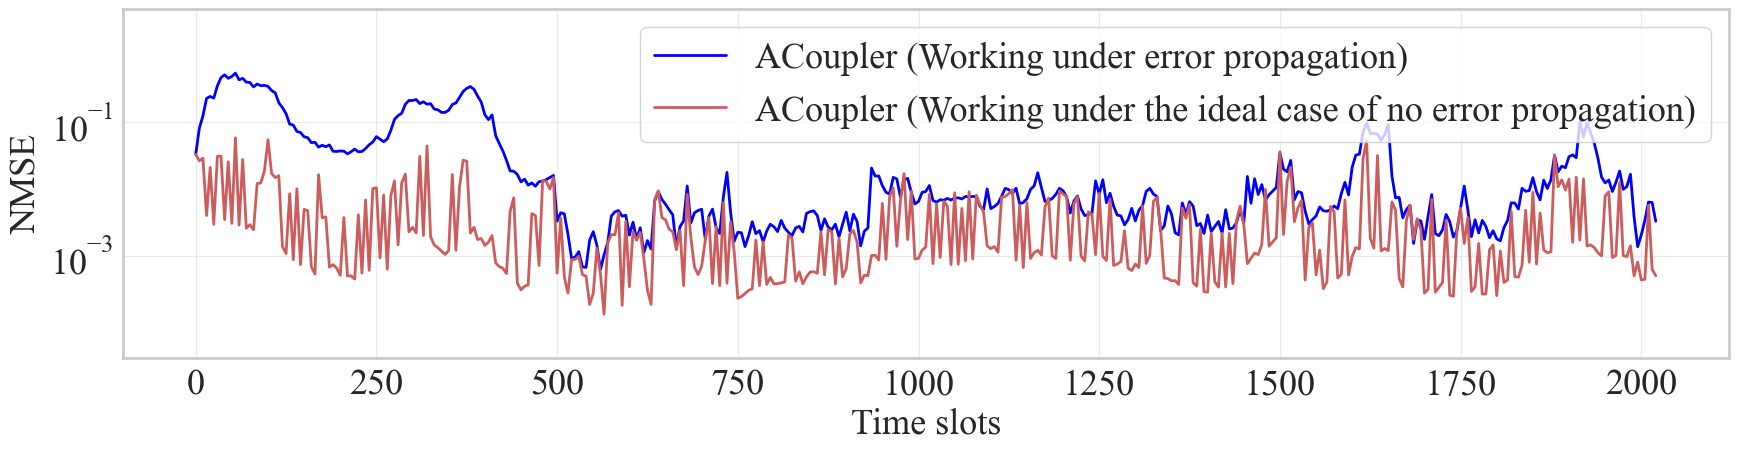

In [8]:
def plot_trace_nmse(
        input_config: str, train_data_config: str, model_name: str,
        trace_filename: str = 'trace_smooth_metrics.h5',
        fig_name: str = "trace_NMSE",
        is_save: bool = True):
    """ 绘制 Trace AR / ideal 曲线 """
    model_dir_name = MODEL_DIR_NAMES[model_name]
    path = os.path.join(EXP_DIR, f'input_{input_config}', train_data_config,
                        model_dir_name, TEST_FOLDER,
                        TEST_DATASET, 'trace_smooth', trace_filename)
    with h5py.File(path, 'r') as f:
        nmse_list = f['nmse_list_ar'][:]
        nmse_list_truth = f['nmse_list_ideal'][:]
    len_deduction = len(nmse_list_truth)

    local_config = {
        "font.size": 26,
        "axes.linewidth": 2,  # 我把 linewidth 也放进来了，这样更整洁
    }
    with plt.rc_context(local_config):
        plt.figure(figsize=(899 / 50, 180 / 50 + 1.5))
        plt.yscale('log')
        plt.ylim(0.00003, 5)
        # plt.yticks([0.0001, 0.001, 0.01, 0.1, 1])
        plt.ylabel('NMSE')

        plt.plot(range(len_deduction)[::5], nmse_list[::5],
                 linewidth=2, color='blue',
                 linestyle='-', label=f'{model_name} (Working under error propagation)')
        plt.plot(range(len_deduction)[::5], nmse_list_truth[::5],
                 linewidth=2, color='indianred',
                 linestyle='-', label=f'{model_name} (Working under the ideal case of no error propagation)')
        plt.legend()
        plt.xlabel('Time slots')
        plt.grid(alpha=0.4)
        plt.tight_layout()
        if is_save:
            save_plot(f"{fig_name}_{model_name}")
        plt.show()

# input_config = '8antx8car'
# model_name = 'AFCoupler'
# trace_filename = 'trace_smooth_metrics_dichasus-0152_pastlen30.h5'
input_config = '3antx3car'
train_data_config = 'data3000_Ncur0or1'
model_name_list = ['ACoupler']
trace_filename = 'trace_smooth_metrics_deepmimo.h5'
# trace_filename = 'trace_smooth_metrics.h5'
fig_name = 'O1data3k_trace_NMSE'
for model_name in model_name_list:
    plot_trace_nmse(input_config, train_data_config, model_name,
                    trace_filename=trace_filename, fig_name=fig_name, is_save=True)